In [1]:
import torch
import tqdm
from visualization import plot_all_poses
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os

In [2]:

# Set up config for optimization
args = {
    'gpu_id':       '0',
    'data_dir':     './data',
    'result_dir':   './exp',
    'save_dir':     'model',
    'train':        True,
    'lr':           0.001,
    'epoch':        50000
}
os.makedirs(args['save_dir'], exist_ok=True)
use_cuda = torch.cuda.is_available()
device = torch.device("cuda:%s" % args['gpu_id'] if use_cuda else "cpu")
dtype = torch.float32

In [3]:
def load_features(path):
    with np.load(path) as data:
        features = data['data']
        frames = data['image_names']
        intri = data['intrinsic']
    return torch.from_numpy(features).to(dtype), frames, torch.from_numpy(intri).to(dtype)

In [10]:
# Load features and intrinsics
features, frames, K = load_features(os.path.join(args['data_dir'],'sift_features.npz'))

In [11]:
def visualize_reprojection(images:list, calib_feature:torch.Tensor, reproj: torch.Tensor, K:torch.Tensor):
    """
    images: [np.array]                  Images
    features_2d: torch.tensor[N,F,2]    Given calibrated features
    reproj: torch.tensor[N,F,2]         Reprojected 3d features normalized by z
    K: torch.tensor[3,3]                     Intrinsics in 
    """
    def p2(calibrated_points):
        """
        Calibrated points to pixels
        """
        key3d = torch.cat([calibrated_points,torch.ones((calibrated_points.shape[0], calibrated_points.shape[1],1)).to(dtype)],dim=-1) @ K.T
        key2d = key3d[:,:,:2]/key3d[:,:,2].unsqueeze(-1)
        key2d[:,:,0] = key2d[:,:,0].clamp(0, 4032)
        key2d[:,:,1] = key2d[:,:,1].clamp(0, 3024)
        return key2d
    
    if calib_feature is not None:
        calib_2d = p2(calib_feature)

    if reproj is not None:
        reproj_2d = p2(reproj)

    fig, ax = plt.subplots(1, len(images),figsize=(20,5))
    for f in range(len(images)):
        ax[f].imshow(images[f])
        if calib_feature is not None:
            ax[f].plot(calib_2d[:,f,0],calib_2d[:,f,1],'ro', markersize = 2)
        if reproj is not None:
            ax[f].plot(reproj_2d[:,f,0],reproj_2d[:,f,1],'bo', markersize = 2)
    plt.show()


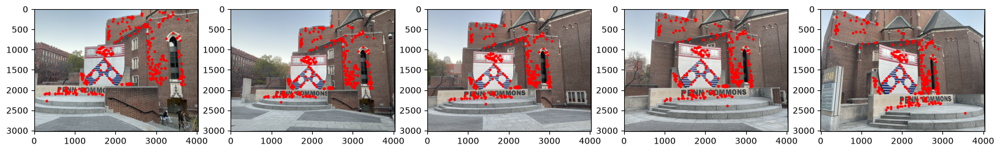

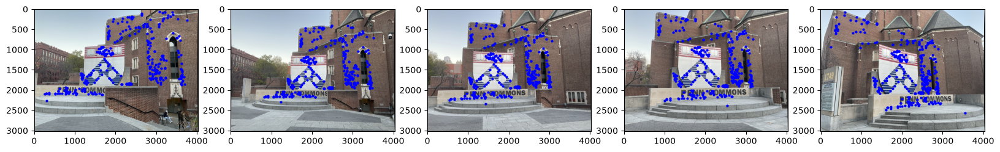

In [12]:
# Load features and frames
images = []
for f in range(frames.shape[0]):
    image = cv2.imread(os.path.join('./data/pennlogo',frames[f]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    images.append(image)
    
# Test with given calibrated features
visualize_reprojection(images, features, None, K)
visualize_reprojection(images, None, features, K)

In [13]:
# Prepare data for BA
batch = {
        'features': features.to(torch.float32),
        'N': features.shape[0],
        'F': len(frames)
    }

  0%|          | 0/50000 [00:00<?, ?it/s, loss=0.0896]

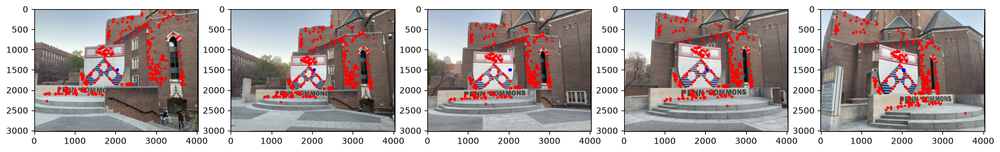

  4%|▍         | 2000/50000 [00:06<00:53, 905.66it/s, loss=0.00112]

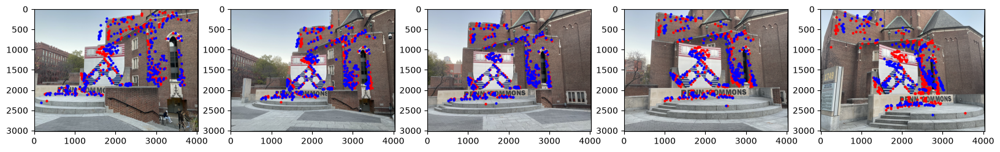

  8%|▊         | 3996/50000 [00:12<00:51, 892.72it/s, loss=0.000187]

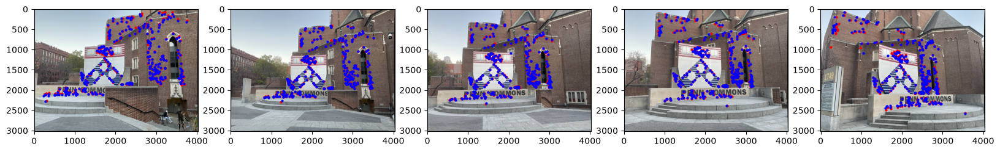

 12%|█▏        | 5933/50000 [00:18<00:51, 862.33it/s, loss=0.000178]

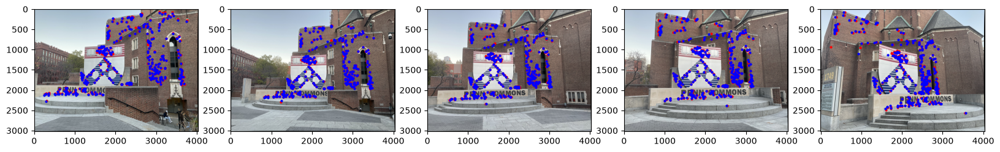

 16%|█▌        | 7936/50000 [00:24<00:47, 886.18it/s, loss=0.000177]

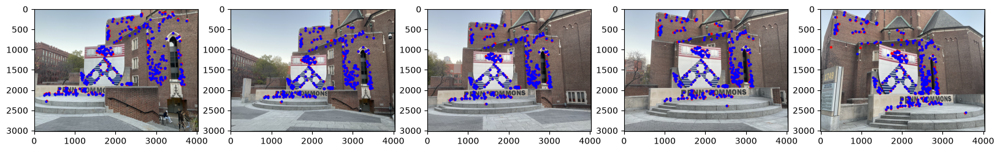

 20%|█▉        | 9999/50000 [00:30<00:45, 888.25it/s, loss=0.000177]

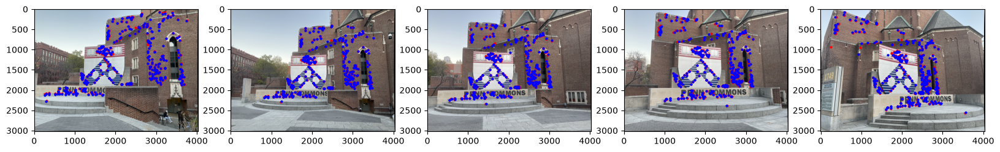

 24%|██▍       | 11940/50000 [00:36<00:43, 869.19it/s, loss=0.000177]

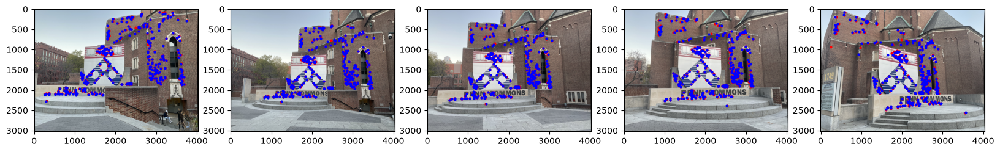

 28%|██▊       | 13940/50000 [00:42<00:52, 689.81it/s, loss=0.000177]

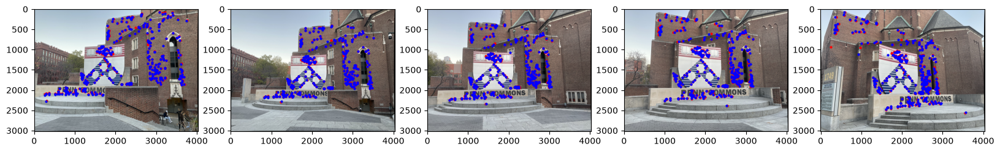

 32%|███▏      | 15979/50000 [00:48<00:36, 940.73it/s, loss=0.000177]

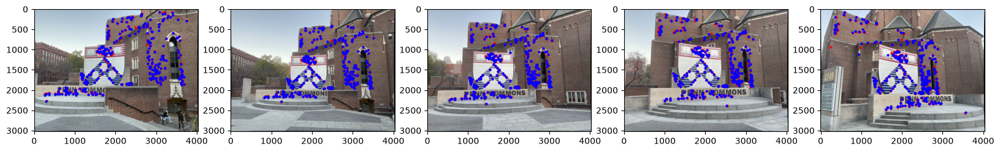

 36%|███▌      | 17930/50000 [00:54<00:35, 896.43it/s, loss=0.000177]

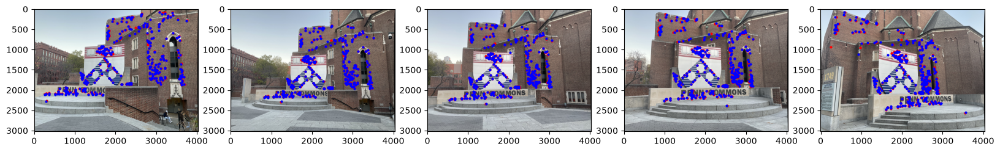

 40%|███▉      | 19929/50000 [01:02<00:34, 865.91it/s, loss=0.000177]

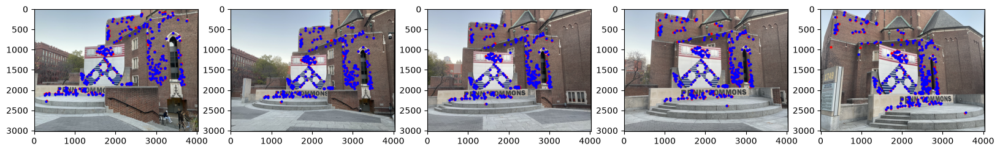

 44%|████▍     | 21925/50000 [01:08<00:32, 852.65it/s, loss=0.000177]

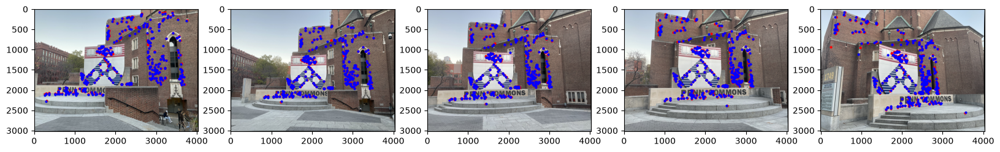

 48%|████▊     | 23948/50000 [01:14<00:27, 936.53it/s, loss=0.000177]

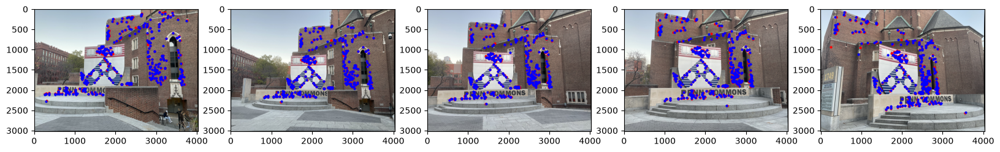

 52%|█████▏    | 25917/50000 [01:20<00:25, 936.99it/s, loss=0.000177]

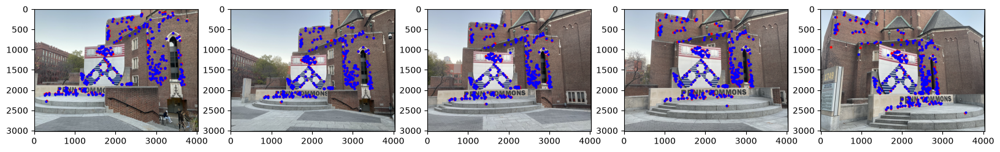

 56%|█████▌    | 27987/50000 [01:25<00:24, 887.83it/s, loss=0.000177]

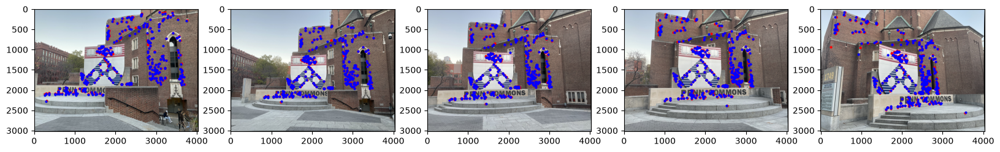

 60%|█████▉    | 29997/50000 [01:32<00:21, 949.31it/s, loss=0.000177]

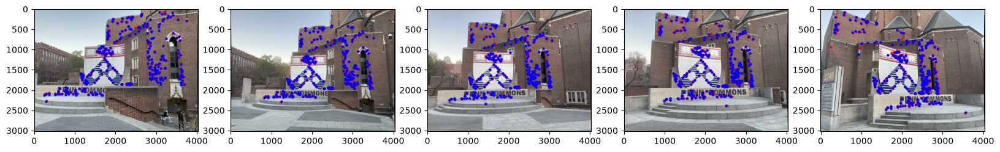

 64%|██████▍   | 31906/50000 [01:37<00:19, 940.36it/s, loss=0.000177]

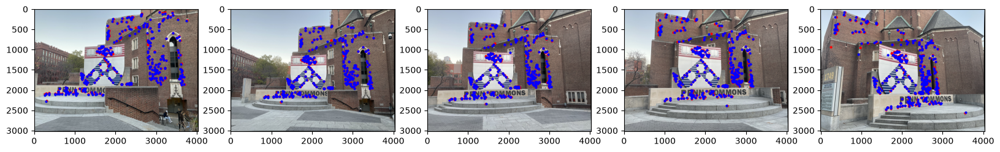

 68%|██████▊   | 33975/50000 [01:43<00:16, 955.56it/s, loss=0.000177]

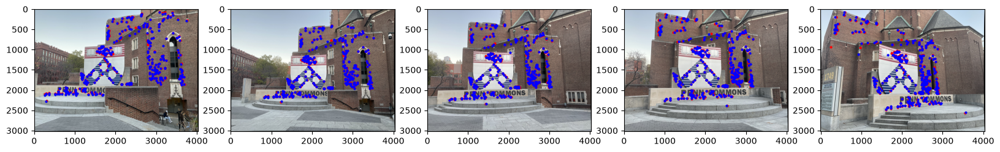

 72%|███████▏  | 35979/50000 [01:48<00:14, 934.92it/s, loss=0.000177]

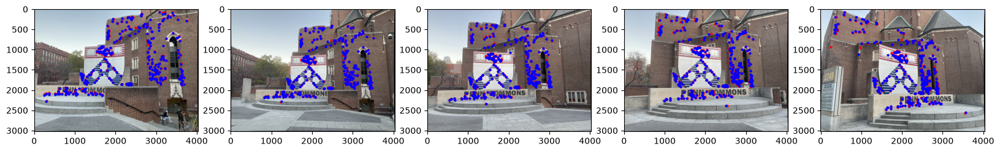

 76%|███████▌  | 37997/50000 [01:54<00:12, 926.38it/s, loss=0.000177]

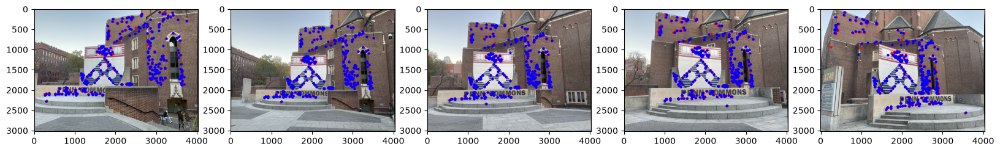

 80%|███████▉  | 39951/50000 [01:59<00:11, 912.29it/s, loss=0.000177]

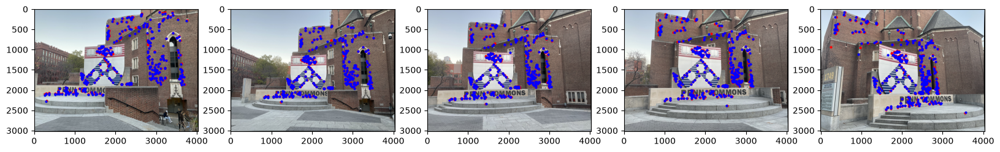

 84%|████████▍ | 41969/50000 [02:04<00:08, 943.96it/s, loss=0.000177]

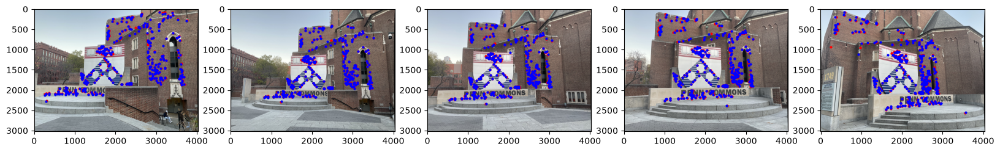

 88%|████████▊ | 43975/50000 [02:10<00:06, 884.07it/s, loss=0.000177]

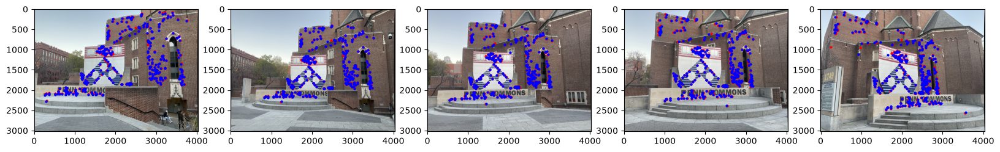

 92%|█████████▏| 45953/50000 [02:16<00:05, 717.74it/s, loss=0.000177]

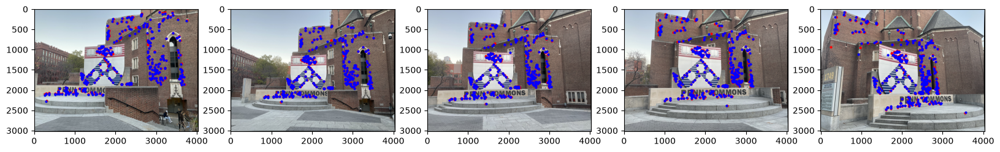

 96%|█████████▌| 47998/50000 [02:21<00:02, 848.90it/s, loss=0.000177]

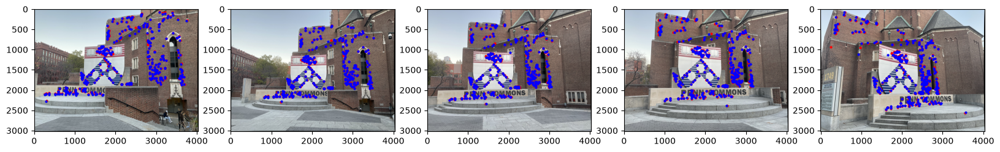

100%|██████████| 50000/50000 [02:27<00:00, 339.52it/s, loss=0.000177]


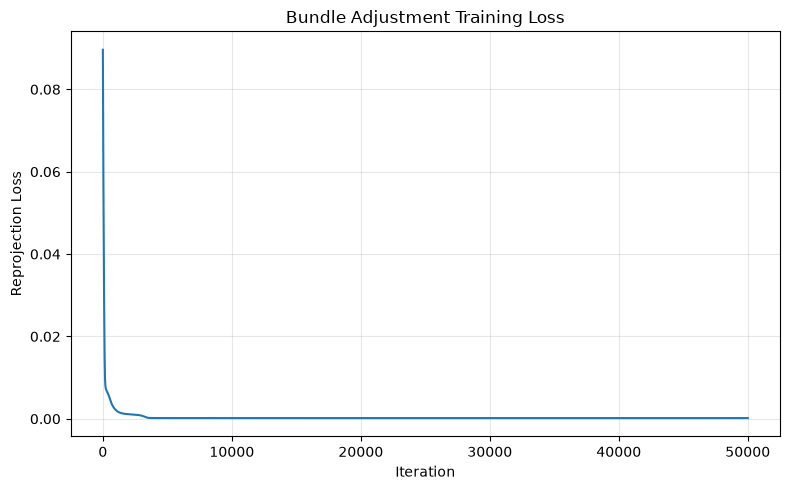

In [15]:
from torch_BA import torch_BA

min_loss = torch.inf
epoch = args['epoch']

BA_backend = torch_BA(batch['F'], batch['N'], batch['features'], device, args['lr'])

loss_history = []  # NEW: Store loss at each iteration

if args['train']:
    pbar = tqdm.tqdm(range(epoch))

    for iter in pbar:
        loss = BA_backend.forward_one_step()

        loss_history.append(float(loss))  # NEW

        pbar.set_postfix({
            'loss': float(loss)
        })

        if iter % 2000 == 0:
            key3d_norm = BA_backend.reprojection(False)
            viz = visualize_reprojection(images, features, key3d_norm, K)

            if loss < min_loss:
                min_loss = float(loss)
                torch.save({
                    'model_state_dict': BA_backend.state_dict(),
                }, '%s/model.pkl' % args['save_dir'])

    # NEW: Plot loss after training finishes
    plt.figure(figsize=(8, 5))
    plt.plot(loss_history)
    plt.xlabel('Iteration')
    plt.ylabel('Reprojection Loss')
    plt.title('Bundle Adjustment Training Loss')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    checkpoint = torch.load('%s/model.pkl' % args['save_dir'], map_location=device)
    BA_backend.load_state_dict(checkpoint['model_state_dict'])
        


theta: torch.Size([5, 3, 3])
trans: torch.Size([5, 3])
key3d: torch.Size([114, 3])


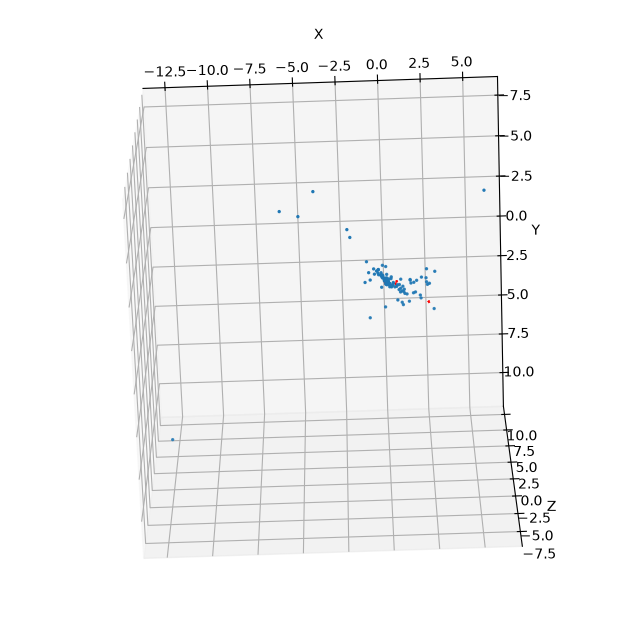

In [9]:
# After optimization you can copy all the code to a .py file and plot the figure with interactive window.
# Set args['Train']=False

theta, trans, key3d = BA_backend.save_parameters(to_rotm=True)

print("theta:", theta.shape)
print("trans:", trans.shape)
print("key3d:", key3d.shape)

theta = torch.inverse(theta)
trans = (theta @ -trans.unsqueeze(-1) ).squeeze(-1)
poses = torch.cat([theta, trans.unsqueeze(-1)], dim=-1) 

plot_all_poses(poses.numpy(), key3d.numpy())

In [18]:
# for colmap parameters, save the parameters for gradescope evaluation
# SUBMIT THIS TO GRADESCOPE
theta, trans, key3d = BA_backend.save_parameters(to_rotm=False)
np.savez("colmap_parameters.npz", theta = theta.numpy(), trans = trans.numpy(), key3d = key3d.numpy())
